# Transcript architecture

Relate annotated transcript features to transcriptional and translational effects.


In [1]:
import json
import re
from collections import defaultdict
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from IPython.display import display
from scipy.stats import spearmanr
from statsmodels.stats.multitest import multipletests

ALPHA = 0.05
REFERENCE = 'Unaffected'
TEST = 'ASD'
ANALYSES = ('input', 'monosome', 'polysome', 'redistribution')
LABELS = {
    'input': 'Input',
    'monosome': 'Monosome',
    'polysome': 'Polysome',
    'redistribution': 'Redistribution',
}
RESULT_FILES = {
    'input': 'inputDifferentialTranscriptAbundance.tsv',
    'monosome': 'monosomeDifferentialTranscriptAbundance.tsv',
    'polysome': 'polysomeDifferentialTranscriptAbundance.tsv',
    'redistribution': 'transcriptRedistribution.tsv',
}
FEATURES = {
    'logFivePrimeUtrLength': {
        'label': 'log(1 + 5′ UTR length)',
        'family': 'primary',
    },
    'fivePrimeUtrGc': {
        'label': '5′ UTR GC fraction',
        'family': 'primary',
    },
    'hasUpstreamAug': {
        'label': 'Upstream AUG present',
        'family': 'primary',
    },
    'hasCandidateUorf': {
        'label': 'Contained candidate uORF',
        'family': 'primary',
    },
    'hasOverlappingUorf': {
        'label': 'Overlapping candidate uORF',
        'family': 'primary',
    },
    'kozakScore': {
        'label': 'Kozak context score',
        'family': 'primary',
    },
    'logCdsLength': {
        'label': 'log(1 + CDS length)',
        'family': 'secondary',
    },
    'logThreePrimeUtrLength': {
        'label': 'log(1 + 3′ UTR length)',
        'family': 'secondary',
    },
}
JOINT_FEATURES = tuple(
    feature for feature in FEATURES if feature != 'hasUpstreamAug'
)
VARIANTS = {
    'primary': {
        'adjust': True,
        'excludeUnstable': True,
        'excludeFdr': False,
        'geneBalanced': False,
        'outcome': 'statistic',
    },
    'unadjusted': {
        'adjust': False,
        'excludeUnstable': True,
        'excludeFdr': False,
        'geneBalanced': False,
        'outcome': 'statistic',
    },
    'includeUnstable': {
        'adjust': True,
        'excludeUnstable': False,
        'excludeFdr': False,
        'geneBalanced': False,
        'outcome': 'statistic',
    },
    'excludeFdr': {
        'adjust': True,
        'excludeUnstable': True,
        'excludeFdr': True,
        'geneBalanced': False,
        'outcome': 'statistic',
    },
    'geneBalanced': {
        'adjust': True,
        'excludeUnstable': True,
        'excludeFdr': False,
        'geneBalanced': True,
        'outcome': 'statistic',
    },
    'effectSize': {
        'adjust': True,
        'excludeUnstable': True,
        'excludeFdr': False,
        'geneBalanced': False,
        'outcome': 'log2FoldChange',
    },
}

sns.set_theme(style = 'ticks', context = 'notebook')


In [2]:
# Locate inputs and validate the result-table contract.


def find_root(start: Path) -> Path:
    for path in (start, *start.parents):
        if (path / 'data').is_dir() and (path / 'results').is_dir():
            return path
    raise FileNotFoundError('Could not find the project data and results directories.')


ROOT = find_root(Path.cwd().resolve())
DATA_DIR = ROOT / 'data'
RESULTS_DIR = ROOT / 'results'
GTF_PATH = DATA_DIR / 'reference' / 'gencode.v50.primary_assembly.annotation.gtf'
FASTA_PATH = DATA_DIR / 'reference' / 'genome.transcripts.fa'
COMPARISON_PATH = RESULTS_DIR / 'transcriptAbundanceComparison.tsv'

required_columns = {
    'transcriptId',
    'parentGeneId',
    'geneName',
    'baseMean',
    'log2FoldChange',
    'statistic',
    'adjustedPValue',
    'meanGeneProportion',
    'significant',
}
effects = {}
parent_maps = []

for analysis, filename in RESULT_FILES.items():
    table = pd.read_csv(RESULTS_DIR / filename, sep = '\t')
    missing = required_columns.difference(table.columns)
    if missing:
        raise ValueError(f'{filename} is missing columns: {sorted(missing)}')
    if table['transcriptId'].duplicated().any():
        raise ValueError(f'{filename} contains duplicate transcript IDs.')
    expected_significant = table['adjustedPValue'].lt(ALPHA).fillna(False)
    if not table['significant'].astype(bool).equals(expected_significant):
        raise ValueError(f'{filename} has inconsistent significance flags.')
    effects[analysis] = table.set_index('transcriptId')
    parent_maps.append(
        table[['transcriptId', 'parentGeneId', 'geneName']].copy()
    )

parent_map = pd.concat(parent_maps, ignore_index = True)
parent_conflicts = parent_map.groupby('transcriptId')['parentGeneId'].nunique()
if parent_conflicts.gt(1).any():
    raise ValueError('A transcript maps to multiple parent genes across results.')
parent_map = parent_map.drop_duplicates('transcriptId').set_index('transcriptId')
target_transcripts = set(parent_map.index)

comparison = pd.read_csv(COMPARISON_PATH, sep = '\t').set_index('transcriptId')
if not target_transcripts.issubset(comparison.index):
    raise ValueError('The transcript comparison table does not cover every result.')

metadata = pd.read_csv(DATA_DIR / 'metadata.tsv', sep = '\t', dtype = 'string')
if set(metadata['condition']) != {REFERENCE, TEST}:
    raise ValueError('Metadata conditions do not match the prespecified contrast.')

with GTF_PATH.open(encoding = 'utf-8') as handle:
    gtf_header = [next(handle).rstrip() for _ in range(4)]
with FASTA_PATH.open(encoding = 'utf-8') as handle:
    fasta_header = next(handle).rstrip()

if 'version 50 (Ensembl 116)' not in gtf_header[0]:
    raise ValueError('The GTF is not GENCODE v50 / Ensembl 116.')
if not fasta_header.startswith('>ENST'):
    raise ValueError('The transcript FASTA does not use GENCODE transcript IDs.')

configuration = pd.DataFrame({
    'setting': [
        'contrast',
        'annotation',
        'transcript FASTA',
        'tested transcript union',
        'primary features',
        'secondary features',
        'joint-model features',
        'association model',
        'multiple testing',
    ],
    'value': [
        f'{TEST} versus {REFERENCE}',
        gtf_header[0].removeprefix('##description: '),
        FASTA_PATH.name,
        len(target_transcripts),
        sum(item['family'] == 'primary' for item in FEATURES.values()),
        sum(item['family'] == 'secondary' for item in FEATURES.values()),
        len(JOINT_FEATURES),
        'within-gene fixed effects with gene-clustered standard errors',
        'BH across every feature and layer',
    ],
})
display(configuration)


,setting,value
0,contrast,ASD versus Unaffected
1,annotation,evidence-based annotation of the human genome ...
2,transcript FASTA,genome.transcripts.fa
3,tested transcript union,62793
4,primary features,6
5,secondary features,2
6,joint-model features,7
7,association model,within-gene fixed effects with gene-clustered ...
8,multiple testing,BH across every feature and layer


In [3]:
# Extract exon and coding coordinates for the tested transcript universe.

attribute_pattern = re.compile(r'(\S+) "([^"]*)";')
transcript_marker = 'transcript_id "'
annotation = {}
segments = {
    feature: defaultdict(list)
    for feature in ('exon', 'CDS', 'start_codon', 'stop_codon', 'UTR')
}
duplicate_transcript_records = 0

with GTF_PATH.open(encoding = 'utf-8') as handle:
    for line in handle:
        if line.startswith('#'):
            continue
        fields = line.rstrip().split('\t', 8)
        feature = fields[2]
        if feature not in {'transcript', *segments}:
            continue
        attributes_text = fields[8]
        marker_start = attributes_text.find(transcript_marker)
        if marker_start < 0:
            continue
        value_start = marker_start + len(transcript_marker)
        value_end = attributes_text.find('"', value_start)
        transcript_id = attributes_text[value_start:value_end]
        if transcript_id not in target_transcripts:
            continue
        start = int(fields[3])
        end = int(fields[4])
        if feature == 'transcript':
            if transcript_id in annotation:
                duplicate_transcript_records += 1
            pairs = attribute_pattern.findall(attributes_text)
            attributes = dict(pairs)
            tags = [value for key, value in pairs if key == 'tag']
            annotation[transcript_id] = {
                'transcriptId': transcript_id,
                'parentGeneId': attributes['gene_id'],
                'geneName': attributes.get('gene_name'),
                'transcriptName': attributes.get('transcript_name'),
                'geneType': attributes.get('gene_type'),
                'transcriptType': attributes.get('transcript_type'),
                'chromosome': fields[0],
                'strand': fields[6],
                'transcriptSpan': end - start + 1,
                'tags': ';'.join(tags),
                'gencodePrimary': 'GENCODE_Primary' in tags,
                'maneSelect': 'MANE_Select' in tags,
                'basic': 'basic' in tags,
            }
        else:
            segments[feature][transcript_id].append((start, end))

missing_gtf = target_transcripts.difference(annotation)
if missing_gtf:
    raise ValueError(f'{len(missing_gtf)} tested transcripts are absent from the GTF.')
if duplicate_transcript_records:
    raise ValueError('The GTF contains duplicate tested transcript records.')


def order_exons(intervals: list[tuple[int, int]], strand: str):
    return sorted(intervals, reverse = strand == '-')


def transcript_coordinate(
    position: int,
    exons: list[tuple[int, int]],
    strand: str,
) -> int:
    offset = 0
    for start, end in exons:
        if start <= position <= end:
            return offset + (position - start if strand == '+' else end - position)
        offset += end - start + 1
    raise ValueError('An annotated coding position is not within an exon.')


def interval_coordinates(
    intervals: list[tuple[int, int]],
    exons: list[tuple[int, int]],
    strand: str,
) -> list[int]:
    coordinates = []
    for start, end in intervals:
        coordinates.extend(
            transcript_coordinate(position, exons, strand)
            for position in range(start, end + 1)
        )
    return coordinates


for transcript_id, record in annotation.items():
    strand = record['strand']
    exons = order_exons(segments['exon'][transcript_id], strand)
    if not exons:
        raise ValueError(f'{transcript_id} has no annotated exons.')
    exon_length = sum(end - start + 1 for start, end in exons)
    cds_intervals = segments['CDS'][transcript_id]
    start_intervals = segments['start_codon'][transcript_id]
    stop_intervals = segments['stop_codon'][transcript_id]
    cds_coordinates = interval_coordinates(cds_intervals, exons, strand)
    start_coordinates = interval_coordinates(start_intervals, exons, strand)
    stop_coordinates = interval_coordinates(stop_intervals, exons, strand)
    record['exonLength'] = exon_length
    record['exonCount'] = len(exons)
    record['cdsLength'] = sum(
        end - start + 1 for start, end in cds_intervals
    )
    record['startCodonLength'] = len(start_coordinates)
    record['stopCodonLength'] = len(stop_coordinates)
    record['annotatedUtrLength'] = sum(
        end - start + 1 for start, end in segments['UTR'][transcript_id]
    )
    record['mainStartIndex'] = (
        min(start_coordinates) if start_coordinates else np.nan
    )
    record['mainStopIndexExclusive'] = (
        max(stop_coordinates) + 1 if stop_coordinates else np.nan
    )
    record['cdsStartIndex'] = (
        min(cds_coordinates) if cds_coordinates else np.nan
    )
    record['cdsEndIndexExclusive'] = (
        max(cds_coordinates) + 1 if cds_coordinates else np.nan
    )

annotation = pd.DataFrame(annotation.values()).set_index('transcriptId')

if not annotation['parentGeneId'].equals(
    parent_map['parentGeneId'].reindex(annotation.index)
):
    raise ValueError('GENCODE and Salmon transcript-to-gene mappings disagree.')

display(
    annotation[['transcriptType', 'exonLength', 'exonCount', 'cdsLength']]
    .describe(include = 'all')
)


,transcriptType,exonLength,exonCount,cdsLength
count,62793,62793.000000,62793.000000,62793.000000
unique,23,NaN,NaN,NaN
top,protein_coding,NaN,NaN,NaN
freq,37733,NaN,NaN,NaN
mean,NaN,2579.861306,8.773191,941.478779
std,NaN,2135.090403,7.337803,1208.897027
min,NaN,69.000000,1.000000,0.000000
25%,NaN,1025.000000,4.000000,177.000000
50%,NaN,1993.000000,7.000000,576.000000
75%,NaN,3424.000000,11.000000,1281.000000


In [4]:
# Stream the run-matched transcript FASTA and derive sequence features.


def fasta_records(path: Path):
    transcript_id = None
    sequence = []
    with path.open(encoding = 'utf-8') as handle:
        for line in handle:
            if line.startswith('>'):
                if transcript_id is not None:
                    yield transcript_id, ''.join(sequence).upper()
                transcript_id = line[1:].split()[0]
                sequence = []
            else:
                sequence.append(line.strip())
    if transcript_id is not None:
        yield transcript_id, ''.join(sequence).upper()


def gc_fraction(sequence: str) -> float:
    canonical = sum(sequence.count(base) for base in 'ACGT')
    if canonical == 0:
        return np.nan
    return (sequence.count('G') + sequence.count('C')) / canonical


def aug_features(sequence: str, main_start: int) -> dict[str, int]:
    upstream_starts = [
        position
        for position in range(max(0, main_start - 2))
        if sequence[position:position + 3] == 'ATG'
        and position + 3 <= main_start
    ]
    contained = 0
    overlapping = 0
    stops = {'TAA', 'TAG', 'TGA'}
    for position in upstream_starts:
        stop_position = next(
            (
                index
                for index in range(position + 3, len(sequence) - 2, 3)
                if sequence[index:index + 3] in stops
            ),
            None,
        )
        if stop_position is not None and stop_position + 3 <= main_start:
            contained += 1
        else:
            overlapping += 1
    return {
        'upstreamAugCount': len(upstream_starts),
        'candidateUorfCount': contained,
        'overlappingUorfCount': overlapping,
    }


sequence_features = {}
seen_fasta = set()
duplicate_fasta_records = 0
valid_bases = set('ACGTN')

for transcript_id, sequence in fasta_records(FASTA_PATH):
    if transcript_id not in target_transcripts:
        continue
    if transcript_id in seen_fasta:
        duplicate_fasta_records += 1
        continue
    seen_fasta.add(transcript_id)
    record = annotation.loc[transcript_id]
    main_start = record['mainStartIndex']
    sequence_length = len(sequence)
    unknown_bases = sum(base not in valid_bases for base in sequence)
    n_count = sequence.count('N')
    feature = {
        'transcriptId': transcript_id,
        'sequenceLength': sequence_length,
        'sequenceGc': gc_fraction(sequence),
        'nFraction': n_count / sequence_length if sequence_length else np.nan,
        'invalidBaseCount': unknown_bases,
        'sequenceLengthMatchesExons': sequence_length == record['exonLength'],
        'mainStartCodon': None,
        'mainStartContext': None,
        'fivePrimeUtrGc': np.nan,
        'upstreamAugCount': np.nan,
        'candidateUorfCount': np.nan,
        'overlappingUorfCount': np.nan,
        'kozakMinusThreePurine': np.nan,
        'kozakPlusFourG': np.nan,
        'kozakScore': np.nan,
    }
    if pd.notna(main_start):
        main_start = int(main_start)
        five_prime_utr = sequence[:main_start]
        feature['mainStartCodon'] = sequence[main_start:main_start + 3]
        feature['fivePrimeUtrGc'] = gc_fraction(five_prime_utr)
        feature.update(aug_features(sequence, main_start))
        if main_start >= 3 and main_start + 3 < sequence_length:
            minus_three = sequence[main_start - 3] in {'A', 'G'}
            plus_four = sequence[main_start + 3] == 'G'
            feature['mainStartContext'] = sequence[
                main_start - 3:main_start + 4
            ]
            feature['kozakMinusThreePurine'] = minus_three
            feature['kozakPlusFourG'] = plus_four
            feature['kozakScore'] = int(minus_three) + int(plus_four)
    sequence_features[transcript_id] = feature

missing_fasta = target_transcripts.difference(seen_fasta)
if missing_fasta:
    raise ValueError(
        f'{len(missing_fasta)} tested transcripts are absent from the FASTA.'
    )
if duplicate_fasta_records:
    raise ValueError('The FASTA contains duplicate tested transcript records.')

sequence_features = pd.DataFrame(sequence_features.values()).set_index(
    'transcriptId'
)
transcript_features = annotation.join(sequence_features, how = 'left')
transcript_features['fivePrimeUtrLength'] = transcript_features[
    'mainStartIndex'
]
transcript_features['threePrimeUtrLength'] = (
    transcript_features['sequenceLength']
    - transcript_features['mainStopIndexExclusive']
)
transcript_features['codingSequenceLength'] = (
    transcript_features['mainStopIndexExclusive']
    - transcript_features['mainStartIndex']
)
transcript_features['utrLengthMatchesAnnotation'] = (
    transcript_features['fivePrimeUtrLength']
    + transcript_features['threePrimeUtrLength']
    + transcript_features['stopCodonLength']
).eq(transcript_features['annotatedUtrLength'])
transcript_features['codingLengthConsistent'] = (
    transcript_features['codingSequenceLength']
    .eq(transcript_features['cdsLength'] + transcript_features['stopCodonLength'])
)
transcript_features['architectureEligible'] = (
    transcript_features['transcriptType'].eq('protein_coding')
    & transcript_features['sequenceLengthMatchesExons']
    & transcript_features['invalidBaseCount'].eq(0)
    & transcript_features['nFraction'].eq(0)
    & transcript_features['startCodonLength'].eq(3)
    & transcript_features['stopCodonLength'].eq(3)
    & transcript_features['mainStartCodon'].eq('ATG')
    & transcript_features['utrLengthMatchesAnnotation']
    & transcript_features['codingLengthConsistent']
)
transcript_features['hasUpstreamAug'] = (
    transcript_features['upstreamAugCount'].gt(0).astype(float)
)
transcript_features['hasCandidateUorf'] = (
    transcript_features['candidateUorfCount'].gt(0).astype(float)
)
transcript_features['hasOverlappingUorf'] = (
    transcript_features['overlappingUorfCount'].gt(0).astype(float)
)
transcript_features['logFivePrimeUtrLength'] = np.log1p(
    transcript_features['fivePrimeUtrLength']
)
transcript_features['logCdsLength'] = np.log1p(
    transcript_features['cdsLength']
)
transcript_features['logThreePrimeUtrLength'] = np.log1p(
    transcript_features['threePrimeUtrLength']
)

display(
    transcript_features.loc[
        transcript_features['architectureEligible'],
        [
            'fivePrimeUtrLength',
            'fivePrimeUtrGc',
            'upstreamAugCount',
            'candidateUorfCount',
            'overlappingUorfCount',
            'kozakScore',
            'cdsLength',
            'threePrimeUtrLength',
        ],
    ].describe()
)


,fivePrimeUtrLength,fivePrimeUtrGc,upstreamAugCount,candidateUorfCount,overlappingUorfCount,kozakScore,cdsLength,threePrimeUtrLength
count,34178.000000,33826.000000,34178.000000,34178.000000,34178.000000,33811.00000,34178.000000,34178.000000
mean,253.583943,0.665992,1.447715,1.190444,0.257271,1.39286,1439.300866,1531.073439
std,261.154429,0.106476,2.894771,2.732462,0.623229,0.61237,1355.999804,1729.926316
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,30.000000,0.000000
25%,96.000000,0.600000,0.000000,0.000000,0.000000,1.00000,585.000000,356.000000
50%,179.000000,0.672383,1.000000,0.000000,0.000000,1.00000,1077.000000,931.000000
75%,323.000000,0.743264,2.000000,1.000000,0.000000,2.00000,1815.000000,2106.000000
max,6231.000000,1.000000,98.000000,98.000000,26.000000,2.00000,20721.000000,24327.000000


In [5]:
# Audit reference concordance and define feature-specific analysis eligibility.

coding = transcript_features['transcriptType'].eq('protein_coding')
complete_coding = (
    coding
    & transcript_features['startCodonLength'].eq(3)
    & transcript_features['stopCodonLength'].eq(3)
)
audit_records = [
    {
        'check': 'tested transcript IDs found in GTF',
        'value': len(annotation),
        'expected': len(target_transcripts),
        'passed': len(annotation) == len(target_transcripts),
    },
    {
        'check': 'tested transcript IDs found in FASTA',
        'value': len(sequence_features),
        'expected': len(target_transcripts),
        'passed': len(sequence_features) == len(target_transcripts),
    },
    {
        'check': 'duplicate tested GTF transcript records',
        'value': duplicate_transcript_records,
        'expected': 0,
        'passed': duplicate_transcript_records == 0,
    },
    {
        'check': 'duplicate tested FASTA records',
        'value': duplicate_fasta_records,
        'expected': 0,
        'passed': duplicate_fasta_records == 0,
    },
    {
        'check': 'FASTA lengths matching spliced exon lengths',
        'value': int(transcript_features['sequenceLengthMatchesExons'].sum()),
        'expected': len(target_transcripts),
        'passed': transcript_features['sequenceLengthMatchesExons'].all(),
    },
    {
        'check': 'sequences containing only A, C, G, T, or N',
        'value': int(transcript_features['invalidBaseCount'].eq(0).sum()),
        'expected': len(target_transcripts),
        'passed': transcript_features['invalidBaseCount'].eq(0).all(),
    },
    {
        'check': 'complete coding UTR lengths plus stop matching GTF UTR',
        'value': int(
            transcript_features.loc[
                complete_coding, 'utrLengthMatchesAnnotation'
            ].sum()
        ),
        'expected': int(complete_coding.sum()),
        'passed': transcript_features.loc[
            complete_coding, 'utrLengthMatchesAnnotation'
        ].all(),
    },
    {
        'check': 'complete coding lengths matching CDS plus stop codon',
        'value': int(
            transcript_features.loc[
                complete_coding, 'codingLengthConsistent'
            ].sum()
        ),
        'expected': int(complete_coding.sum()),
        'passed': transcript_features.loc[
            complete_coding, 'codingLengthConsistent'
        ].all(),
    },
    {
        'check': 'architecture-eligible transcripts',
        'value': int(transcript_features['architectureEligible'].sum()),
        'expected': '> 10000',
        'passed': transcript_features['architectureEligible'].sum() > 10000,
    },
]
feature_audit = pd.DataFrame(audit_records)

if not feature_audit['passed'].all():
    display(feature_audit.loc[~feature_audit['passed']])
    raise ValueError('A transcript-reference audit failed.')

eligibility_records = []
for analysis in ANALYSES:
    table = effects[analysis].join(
        transcript_features.drop(columns = ['parentGeneId', 'geneName']),
        how = 'left',
    )
    for feature, specification in FEATURES.items():
        eligible = (
            table['architectureEligible']
            & table['statistic'].notna()
            & table[feature].notna()
        )
        eligibility_records.append({
            'analysis': analysis,
            'feature': feature,
            'featureLabel': specification['label'],
            'featureFamily': specification['family'],
            'testedTranscripts': len(table),
            'architectureEligibleTranscripts': int(eligible.sum()),
            'eligibleGenes': table.loc[eligible, 'parentGeneId'].nunique(),
        })

feature_eligibility = pd.DataFrame(eligibility_records)
display(feature_audit)
display(feature_eligibility)


,check,value,expected,passed
0,tested transcript IDs found in GTF,62793,62793,True
1,tested transcript IDs found in FASTA,62793,62793,True
2,duplicate tested GTF transcript records,0,0,True
3,duplicate tested FASTA records,0,0,True
4,FASTA lengths matching spliced exon lengths,62793,62793,True
5,"sequences containing only A, C, G, T, or N",62793,62793,True
6,complete coding UTR lengths plus stop matching...,34253,34253,True
7,complete coding lengths matching CDS plus stop...,34253,34253,True
8,architecture-eligible transcripts,34178,> 10000,True


,analysis,feature,featureLabel,featureFamily,testedTranscripts,architectureEligibleTranscripts,eligibleGenes
0,input,logFivePrimeUtrLength,log(1 + 5′ UTR length),primary,47878,27197,11409
1,input,fivePrimeUtrGc,5′ UTR GC fraction,primary,47878,26913,11374
2,input,hasUpstreamAug,Upstream AUG present,primary,47878,27197,11409
3,input,hasCandidateUorf,Contained candidate uORF,primary,47878,27197,11409
4,input,hasOverlappingUorf,Overlapping candidate uORF,primary,47878,27197,11409
5,input,kozakScore,Kozak context score,primary,47878,26907,11373
6,input,logCdsLength,log(1 + CDS length),secondary,47878,27197,11409
7,input,logThreePrimeUtrLength,log(1 + 3′ UTR length),secondary,47878,27197,11409
8,monosome,logFivePrimeUtrLength,log(1 + 5′ UTR length),primary,37990,20128,9453
9,monosome,fivePrimeUtrGc,5′ UTR GC fraction,primary,37990,19952,9402


In [6]:
# Fit gene-fixed-effect models with expression and isoform proportion covariates.


def adjust_pvalues(table: pd.DataFrame) -> pd.DataFrame:
    table = table.copy()
    table['adjustedPValue'] = np.nan
    finite = table['pValue'].notna()
    table.loc[finite, 'adjustedPValue'] = multipletests(
        table.loc[finite, 'pValue'],
        method = 'fdr_bh',
    )[1]
    table['significant'] = table['adjustedPValue'].lt(ALPHA).fillna(False)
    return table


def prepare_model_table(analysis: str) -> pd.DataFrame:
    effect_columns = [
        'parentGeneId',
        'geneName',
        'baseMean',
        'meanGeneProportion',
        'statistic',
        'log2FoldChange',
        'adjustedPValue',
    ]
    feature_columns = [*FEATURES, 'architectureEligible']
    table = effects[analysis][effect_columns].join(
        transcript_features[feature_columns],
        how = 'left',
    )
    table = table.join(
        comparison[
            [f'{analysis}StructuralZero', f'{analysis}ExtremeEffect']
        ],
        how = 'left',
    )
    table = table.loc[table['architectureEligible']].copy()
    table['unstable'] = (
        table[f'{analysis}StructuralZero'].fillna(False).astype(bool)
        | table[f'{analysis}ExtremeEffect'].fillna(False).astype(bool)
    )
    table['fdr'] = table['adjustedPValue'].lt(ALPHA).fillna(False)
    table['logBaseMean'] = np.log1p(table['baseMean'])
    proportion = table['meanGeneProportion'].clip(1e-6, 1 - 1e-6)
    table['logitGeneProportion'] = np.log(proportion / (1 - proportion))
    return table[[
        'parentGeneId',
        'geneName',
        'statistic',
        'log2FoldChange',
        *FEATURES,
        'logBaseMean',
        'logitGeneProportion',
        'unstable',
        'fdr',
    ]]


def fit_model(
    analysis: str,
    variant: str,
    features: list[str],
) -> list[dict]:
    specification = VARIANTS[variant]
    table = prepare_model_table(analysis)
    if specification['excludeUnstable']:
        table = table.loc[~table['unstable']]
    if specification['excludeFdr']:
        table = table.loc[~table['fdr']]
    covariates = (
        ['logBaseMean', 'logitGeneProportion']
        if specification['adjust']
        else []
    )
    outcome = specification['outcome']
    predictors = [*features, *covariates]
    variables = [outcome, *predictors]
    table = table.dropna(subset = ['parentGeneId', *variables]).copy()
    gene_size = table.groupby('parentGeneId')[outcome].transform('size')
    table = table.loc[gene_size >= 2].copy()
    if len(features) == 1:
        gene_variation = table.groupby('parentGeneId')[features[0]].transform(
            'nunique'
        )
        table = table.loc[gene_variation >= 2].copy()
    if table['parentGeneId'].nunique() < 100:
        raise ValueError(f'Insufficient genes for {analysis} / {features}.')

    centered = table[variables] - table.groupby('parentGeneId')[
        variables
    ].transform('mean')
    standard_deviations = centered.std(ddof = 1)
    if standard_deviations.le(0).any():
        raise ValueError(f'A model variable has zero variance for {features}.')
    standardized = centered / standard_deviations
    y = standardized[outcome].to_numpy()
    design = standardized[predictors].to_numpy()
    groups = table['parentGeneId'].to_numpy()
    if specification['geneBalanced']:
        weights = 1 / table.groupby('parentGeneId')[outcome].transform('size')
        model = sm.WLS(y, design, weights = weights.to_numpy())
    else:
        model = sm.OLS(y, design)
    fit = model.fit(
        cov_type = 'cluster',
        cov_kwds = {'groups': groups, 'use_correction': True},
        use_t = True,
    )

    confidence_intervals = fit.conf_int(alpha = ALPHA)
    records = []
    for feature in features:
        feature_index = predictors.index(feature)
        x = design[:, feature_index]
        other_indices = [
            index for index in range(design.shape[1]) if index != feature_index
        ]
        if other_indices:
            other = design[:, other_indices]
            x_residual = x - other @ np.linalg.lstsq(
                other,
                x,
                rcond = None,
            )[0]
            y_residual = y - other @ np.linalg.lstsq(
                other,
                y,
                rcond = None,
            )[0]
        else:
            x_residual = x.copy()
            y_residual = y.copy()
        covariance = pd.Series(x_residual * y_residual, index = table.index)
        gene_covariance = covariance.groupby(table['parentGeneId']).sum()
        total_absolute_covariance = gene_covariance.abs().sum()
        top_gene = gene_covariance.abs().idxmax()
        top_gene_names = parent_map.loc[
            parent_map['parentGeneId'].eq(top_gene), 'geneName'
        ].dropna()
        residual_fraction = np.square(x_residual).sum() / np.square(x).sum()
        records.append({
            'analysis': analysis,
            'feature': feature,
            'featureLabel': FEATURES[feature]['label'],
            'featureFamily': FEATURES[feature]['family'],
            'variant': variant,
            'outcome': outcome,
            'transcripts': len(table),
            'genes': table['parentGeneId'].nunique(),
            'standardizedCoefficient': fit.params[feature_index],
            'standardError': fit.bse[feature_index],
            'confidenceIntervalLow': confidence_intervals[feature_index, 0],
            'confidenceIntervalHigh': confidence_intervals[feature_index, 1],
            'tStatistic': fit.tvalues[feature_index],
            'pValue': fit.pvalues[feature_index],
            'varianceInflationFactor': 1 / residual_fraction,
            'designConditionNumber': fit.condition_number,
            'topInfluenceGeneId': top_gene,
            'topInfluenceGeneName': (
                top_gene_names.iloc[0] if len(top_gene_names) else np.nan
            ),
            'topGeneCovarianceFraction': (
                gene_covariance.abs().max() / total_absolute_covariance
                if total_absolute_covariance
                else np.nan
            ),
        })
    return records


marginal_records = []
for analysis in ANALYSES:
    for feature in FEATURES:
        marginal_records.extend(
            fit_model(analysis, 'primary', [feature])
        )
marginal_association = adjust_pvalues(pd.DataFrame(marginal_records))
marginal_association.insert(0, 'model', 'marginal')
marginal_association = marginal_association.sort_values(
    ['adjustedPValue', 'analysis', 'feature']
)

joint_records = []
for variant in VARIANTS:
    for analysis in ANALYSES:
        joint_records.extend(
            fit_model(analysis, variant, list(JOINT_FEATURES))
        )

feature_sensitivity = pd.concat(
    [
        adjust_pvalues(table)
        for _, table in pd.DataFrame(joint_records).groupby(
            'variant',
            sort = False,
        )
    ],
    ignore_index = True,
)
feature_sensitivity.insert(0, 'model', 'joint')
feature_association = feature_sensitivity.loc[
    feature_sensitivity['variant'].eq('primary')
].copy()
feature_association = feature_association.sort_values(
    ['adjustedPValue', 'analysis', 'feature']
)

primary_coefficients = feature_association.set_index(
    ['analysis', 'feature']
)['standardizedCoefficient']
feature_sensitivity['primaryCoefficient'] = feature_sensitivity.set_index(
    ['analysis', 'feature']
).index.map(primary_coefficients)
feature_sensitivity['directionConcordant'] = np.sign(
    feature_sensitivity['standardizedCoefficient']
).eq(np.sign(feature_sensitivity['primaryCoefficient']))

sensitivity_summary = []
for variant, table in feature_sensitivity.groupby('variant', sort = False):
    correlation = spearmanr(
        table['primaryCoefficient'],
        table['standardizedCoefficient'],
    )
    sensitivity_summary.append({
        'variant': variant,
        'associations': len(table),
        'directionConcordance': table['directionConcordant'].mean(),
        'coefficientSpearmanRho': correlation.statistic,
        'fdrAssociations': int(table['significant'].sum()),
        'maximumTopGeneCovarianceFraction': (
            table['topGeneCovarianceFraction'].max()
        ),
        'maximumVarianceInflationFactor': (
            table['varianceInflationFactor'].max()
        ),
        'maximumDesignConditionNumber': table['designConditionNumber'].max(),
    })
sensitivity_summary = pd.DataFrame(sensitivity_summary)

model_comparison = marginal_association[[
    'analysis',
    'feature',
    'standardizedCoefficient',
    'adjustedPValue',
    'significant',
]].merge(
    feature_association[[
        'analysis',
        'feature',
        'standardizedCoefficient',
        'adjustedPValue',
        'significant',
        'varianceInflationFactor',
    ]],
    on = ['analysis', 'feature'],
    suffixes = ('Marginal', 'Joint'),
    validate = 'one_to_one',
)
model_comparison['retainedAfterJointAdjustment'] = (
    model_comparison['significantMarginal']
    & model_comparison['significantJoint']
)

model_audit = pd.DataFrame([
    {
        'check': 'maximum joint-model variance inflation factor',
        'value': feature_association['varianceInflationFactor'].max(),
        'expected': '< 10',
        'passed': feature_association['varianceInflationFactor'].max() < 10,
    },
    {
        'check': 'maximum joint-model condition number',
        'value': feature_association['designConditionNumber'].max(),
        'expected': '< 30',
        'passed': feature_association['designConditionNumber'].max() < 30,
    },
    {
        'check': 'maximum single-gene covariance fraction',
        'value': feature_sensitivity['topGeneCovarianceFraction'].max(),
        'expected': '< 0.05',
        'passed': feature_sensitivity['topGeneCovarianceFraction'].max() < 0.05,
    },
])
if not model_audit['passed'].all():
    display(model_audit.loc[~model_audit['passed']])
    raise ValueError('A joint-model stability audit failed.')
feature_audit = pd.concat([feature_audit, model_audit], ignore_index = True)

display(feature_association)
display(marginal_association)
display(sensitivity_summary)
display(model_comparison)


,model,analysis,feature,featureLabel,featureFamily,variant,outcome,transcripts,genes,standardizedCoefficient,...,confidenceIntervalHigh,tStatistic,pValue,varianceInflationFactor,designConditionNumber,topInfluenceGeneId,topInfluenceGeneName,topGeneCovarianceFraction,adjustedPValue,significant
19,joint,polysome,logCdsLength,log(1 + CDS length),secondary,primary,statistic,20513,6227,0.165655,...,0.186568,15.527981,2.226070e-53,1.277174,9.403623,ENSG00000174748.24,RPL15,0.003720,6.232995e-52,True
26,joint,redistribution,logCdsLength,log(1 + CDS length),secondary,primary,statistic,11679,3843,0.101637,...,0.128350,7.459524,1.067730e-13,1.441142,7.839349,ENSG00000174748.24,RPL15,0.006776,1.494821e-12,True
5,joint,input,logCdsLength,log(1 + CDS length),secondary,primary,statistic,22145,6731,-0.065141,...,-0.047524,-7.248581,4.681979e-13,1.302443,9.398032,ENSG00000186230.8,ZNF749,0.008167,4.369847e-12,True
14,joint,polysome,logFivePrimeUtrLength,log(1 + 5′ UTR length),primary,primary,statistic,20513,6227,0.069257,...,0.090261,6.463941,1.097468e-10,1.771407,9.403623,ENSG00000241553.15,ARPC4,0.003796,7.682278e-10,True
9,joint,monosome,hasCandidateUorf,Contained candidate uORF,primary,primary,statistic,15124,4681,0.075646,...,0.099826,6.133368,9.312427e-10,1.556923,9.094887,ENSG00000141552.20,ANAPC11,0.005283,5.214959e-09,True
15,joint,polysome,fivePrimeUtrGc,5′ UTR GC fraction,primary,primary,statistic,20513,6227,0.051306,...,0.067805,6.096132,1.151752e-09,1.170810,9.403623,ENSG00000161904.15,LEMD2,0.003662,5.374843e-09,True
6,joint,input,logThreePrimeUtrLength,log(1 + 3′ UTR length),secondary,primary,statistic,22145,6731,0.052071,...,0.070383,5.574182,2.583352e-08,1.709950,9.398032,ENSG00000136709.14,WDR33,0.004690,1.033341e-07,True
27,joint,redistribution,logThreePrimeUtrLength,log(1 + 3′ UTR length),secondary,primary,statistic,11679,3843,-0.068267,...,-0.043463,-5.395878,7.230526e-08,1.441318,7.839349,ENSG00000100568.13,VTI1B,0.006033,2.530684e-07,True
17,joint,polysome,hasOverlappingUorf,Overlapping candidate uORF,primary,primary,statistic,20513,6227,-0.044105,...,-0.027886,-5.330907,1.011615e-07,1.099792,9.403623,ENSG00000163684.13,RPP14,0.004312,3.147247e-07,True
7,joint,monosome,logFivePrimeUtrLength,log(1 + 5′ UTR length),primary,primary,statistic,15124,4681,0.061162,...,0.086735,4.688834,2.825801e-06,1.774604,9.094887,ENSG00000189403.17,HMGB1,0.005370,7.912242e-06,True


,model,analysis,feature,featureLabel,featureFamily,variant,outcome,transcripts,genes,standardizedCoefficient,...,confidenceIntervalHigh,tStatistic,pValue,varianceInflationFactor,designConditionNumber,topInfluenceGeneId,topInfluenceGeneName,topGeneCovarianceFraction,adjustedPValue,significant
22,marginal,polysome,logCdsLength,log(1 + CDS length),secondary,primary,statistic,18109,5154,0.175303,...,0.196166,16.472550,1.870091e-59,1.176373,6.327034,ENSG00000186230.8,ZNF749,0.003401,5.984290e-58,True
11,marginal,monosome,hasCandidateUorf,Contained candidate uORF,primary,primary,statistic,5955,1528,0.152185,...,0.182310,9.909112,1.781348e-22,1.102429,5.732809,ENSG00000141552.20,ANAPC11,0.007826,2.850156e-21,True
10,marginal,monosome,hasUpstreamAug,Upstream AUG present,primary,primary,statistic,6232,1609,0.142955,...,0.172013,9.649458,1.861088e-21,1.104889,5.708818,ENSG00000141552.20,ANAPC11,0.007802,1.985160e-20,True
17,marginal,polysome,fivePrimeUtrGc,5′ UTR GC fraction,primary,primary,statistic,19394,5791,0.071811,...,0.087540,8.950183,4.702140e-19,1.001778,5.852417,ENSG00000159176.16,CSRP1,0.004157,3.761712e-18,True
30,marginal,redistribution,logCdsLength,log(1 + CDS length),secondary,primary,statistic,10194,3176,0.120972,...,0.148381,8.653878,7.778542e-18,1.324609,5.625167,ENSG00000174748.24,RPL15,0.006507,4.978267e-17,True
6,marginal,input,logCdsLength,log(1 + CDS length),secondary,primary,statistic,18460,5068,-0.081708,...,-0.063042,-8.581593,1.228402e-17,1.240538,6.318503,ENSG00000186230.8,ZNF749,0.008783,6.551478e-17,True
8,marginal,monosome,logFivePrimeUtrLength,log(1 + 5′ UTR length),primary,primary,statistic,14430,4388,0.089326,...,0.110927,8.106883,6.675861e-16,1.114270,5.713605,ENSG00000181991.18,MRPS11,0.005701,3.051822e-15,True
7,marginal,input,logThreePrimeUtrLength,log(1 + 3′ UTR length),secondary,primary,statistic,18282,5130,0.070441,...,0.089927,7.086799,1.558317e-12,1.624255,7.002914,ENSG00000136709.14,WDR33,0.005059,6.233268e-12,True
31,marginal,redistribution,logThreePrimeUtrLength,log(1 + 3′ UTR length),secondary,primary,statistic,9616,2935,-0.093049,...,-0.067087,-7.027577,2.602451e-12,1.397778,5.857663,ENSG00000100568.13,VTI1B,0.006461,9.253161e-12,True
20,marginal,polysome,hasOverlappingUorf,Overlapping candidate uORF,primary,primary,statistic,5809,1473,-0.102659,...,-0.073417,-6.886266,8.456250e-12,1.031240,5.995071,ENSG00000163684.13,RPP14,0.004658,2.706000e-11,True


,variant,associations,directionConcordance,coefficientSpearmanRho,fdrAssociations,maximumTopGeneCovarianceFraction,maximumVarianceInflationFactor,maximumDesignConditionNumber
0,primary,28,1.000000,1.000000,20,0.013667,1.869287,9.403623
1,unadjusted,28,0.964286,0.964970,20,0.013709,1.576310,2.209644
2,includeUnstable,28,0.964286,0.980296,16,0.015828,1.826392,9.396786
3,excludeFdr,28,1.000000,0.986316,21,0.007223,1.874828,9.412184
4,geneBalanced,28,0.964286,0.975917,17,0.013667,1.869287,9.609566
5,effectSize,28,0.857143,0.898194,17,0.011979,1.869287,9.403623


,analysis,feature,standardizedCoefficientMarginal,adjustedPValueMarginal,significantMarginal,standardizedCoefficientJoint,adjustedPValueJoint,significantJoint,varianceInflationFactor,retainedAfterJointAdjustment
0,polysome,logCdsLength,0.175303,5.984290e-58,True,0.165655,6.232995e-52,True,1.277174,True
1,monosome,hasCandidateUorf,0.152185,2.850156e-21,True,0.075646,5.214959e-09,True,1.556923,True
2,polysome,fivePrimeUtrGc,0.071811,3.761712e-18,True,0.051306,5.374843e-09,True,1.170810,True
3,redistribution,logCdsLength,0.120972,4.978267e-17,True,0.101637,1.494821e-12,True,1.441142,True
4,input,logCdsLength,-0.081708,6.551478e-17,True,-0.065141,4.369847e-12,True,1.302443,True
5,monosome,logFivePrimeUtrLength,0.089326,3.051822e-15,True,0.061162,7.912242e-06,True,1.774604,True
6,input,logThreePrimeUtrLength,0.070441,6.233268e-12,True,0.052071,1.033341e-07,True,1.709950,True
7,redistribution,logThreePrimeUtrLength,-0.093049,9.253161e-12,True,-0.068267,2.530684e-07,True,1.441318,True
8,polysome,hasOverlappingUorf,-0.102659,2.706000e-11,True,-0.044105,3.147247e-07,True,1.099792,True
9,polysome,logThreePrimeUtrLength,-0.079183,7.913706e-11,True,-0.035773,2.642323e-03,True,1.706014,True


In [7]:
# Summarize transcript-level discoveries without treating them as independent tests.

abundance_candidate = comparison[
    [f'{analysis}Fdr' for analysis in ANALYSES]
].fillna(False).any(axis = 1)
dtu_path = RESULTS_DIR / 'dtuTranscriptComparison.tsv'
dtu = None
dtu_columns = []
dtu_adjusted_columns = []
dtu_candidate_ids = set()

if dtu_path.is_file():
    dtu = pd.read_csv(dtu_path, sep = '\t').set_index('transcriptId')
    dtu_columns = [
        f'{analysis}TranscriptSignificant'
        for analysis in ANALYSES
        if f'{analysis}TranscriptSignificant' in dtu.columns
    ]
    dtu_adjusted_columns = [
        f'{analysis}StageTranscriptAdjustedPValue'
        for analysis in ANALYSES
        if f'{analysis}StageTranscriptAdjustedPValue' in dtu.columns
    ]
    dtu_candidate_ids = set(
        dtu.index[dtu[dtu_columns].fillna(False).any(axis = 1)]
    )

candidate_ids = set(comparison.index[abundance_candidate]) | dtu_candidate_ids
if not dtu_candidate_ids.issubset(comparison.index):
    raise ValueError('A confirmed DTU transcript is absent from abundance results.')
candidate = comparison.loc[sorted(candidate_ids)].copy()
candidate = candidate.join(
    transcript_features.drop(columns = ['parentGeneId', 'geneName']),
    how = 'left',
)
candidate['abundanceFdrLayers'] = candidate.apply(
    lambda row: ';'.join(
        analysis
        for analysis in ANALYSES
        if pd.notna(row.get(f'{analysis}Fdr'))
        and bool(row.get(f'{analysis}Fdr'))
    ),
    axis = 1,
)

if dtu is not None:
    candidate = candidate.join(
        dtu[[*dtu_columns, *dtu_adjusted_columns]],
        how = 'left',
    )
    candidate['dtuLayers'] = candidate.apply(
        lambda row: ';'.join(
            column.removesuffix('TranscriptSignificant')
            for column in dtu_columns
            if pd.notna(row.get(column)) and bool(row.get(column))
        ),
        axis = 1,
    )
else:
    candidate['dtuLayers'] = ''

candidate['minimumAdjustedPValue'] = candidate[
    [f'{analysis}AdjustedPValue' for analysis in ANALYSES]
].min(axis = 1)
candidate['minimumDtuAdjustedPValue'] = (
    candidate[dtu_adjusted_columns].min(axis = 1)
    if dtu_adjusted_columns
    else np.nan
)
candidate['candidateRankPValue'] = candidate[
    ['minimumAdjustedPValue', 'minimumDtuAdjustedPValue']
].min(axis = 1)
candidate = candidate.sort_values(
    ['candidateRankPValue', 'geneName', 'transcriptId']
)

candidate_columns = [
    'parentGeneId',
    'geneName',
    'abundanceFdrLayers',
    'dtuLayers',
    'minimumAdjustedPValue',
    'minimumDtuAdjustedPValue',
    'architectureEligible',
    'transcriptName',
    'transcriptType',
    'fivePrimeUtrLength',
    'fivePrimeUtrGc',
    'upstreamAugCount',
    'candidateUorfCount',
    'overlappingUorfCount',
    'kozakScore',
    'cdsLength',
    'threePrimeUtrLength',
]
candidate_summary = candidate[candidate_columns].reset_index()
display(candidate_summary.head(30))


,transcriptId,parentGeneId,geneName,abundanceFdrLayers,dtuLayers,minimumAdjustedPValue,minimumDtuAdjustedPValue,architectureEligible,transcriptName,transcriptType,fivePrimeUtrLength,fivePrimeUtrGc,upstreamAugCount,candidateUorfCount,overlappingUorfCount,kozakScore,cdsLength,threePrimeUtrLength
0,ENST00000301821.11,ENSG00000168028.17,RPSA,,input,1.061540e-01,0.0,True,RPSA-201,protein_coding,78.0,0.487179,0.0,0.0,0.0,1.0,885,174.0
1,ENST00000458478.7,ENSG00000168028.17,RPSA,,input,7.029651e-02,0.0,True,RPSA-204,protein_coding,107.0,0.495327,0.0,0.0,0.0,1.0,885,70.0
2,ENST00000457233.6,ENSG00000242086.9,MUC20-OT1,input;monosome;polysome,,1.081257e-120,NaN,False,MUC20-OT1-221,lncRNA,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN
3,ENST00001061868.1,ENSG00000182774.15,RPS17,input;monosome;polysome,,1.291244e-90,NaN,False,RPS17-221,nonsense_mediated_decay,26.0,0.538462,0.0,0.0,0.0,2.0,180,661.0
4,ENST00000393655.4,ENSG00000008196.14,TFAP2B,monosome;polysome,,2.580836e-47,NaN,True,TFAP2B-202,protein_coding,21.0,0.476190,1.0,0.0,1.0,0.0,1380,4227.0
5,ENST00000488803.1,ENSG00000240342.3,RPS2P5,input;monosome;polysome,,6.825639e-42,NaN,False,RPS2P5-201,processed_pseudogene,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN
6,ENST00000849477.1,ENSG00000259551.2,ENSG00000259551,monosome,,2.243258e-36,NaN,False,ENST00000849477,lncRNA,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN
7,ENST00000685247.3,ENSG00000289047.3,ENSG00000289047,input;monosome,,2.106905e-33,NaN,False,ENST00000685247,lncRNA,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN
8,ENST00000320996.15,ENSG00000180957.20,PITPNB,monosome;redistribution,,2.736158e-32,NaN,True,PITPNB-201,protein_coding,65.0,0.738462,0.0,0.0,0.0,2.0,816,1944.0
9,ENST00000380870.9,ENSG00000172687.16,ZNF738,input;monosome;polysome,,9.873243e-31,NaN,True,ZNF738-202,protein_coding,214.0,0.593458,1.0,1.0,0.0,2.0,351,639.0


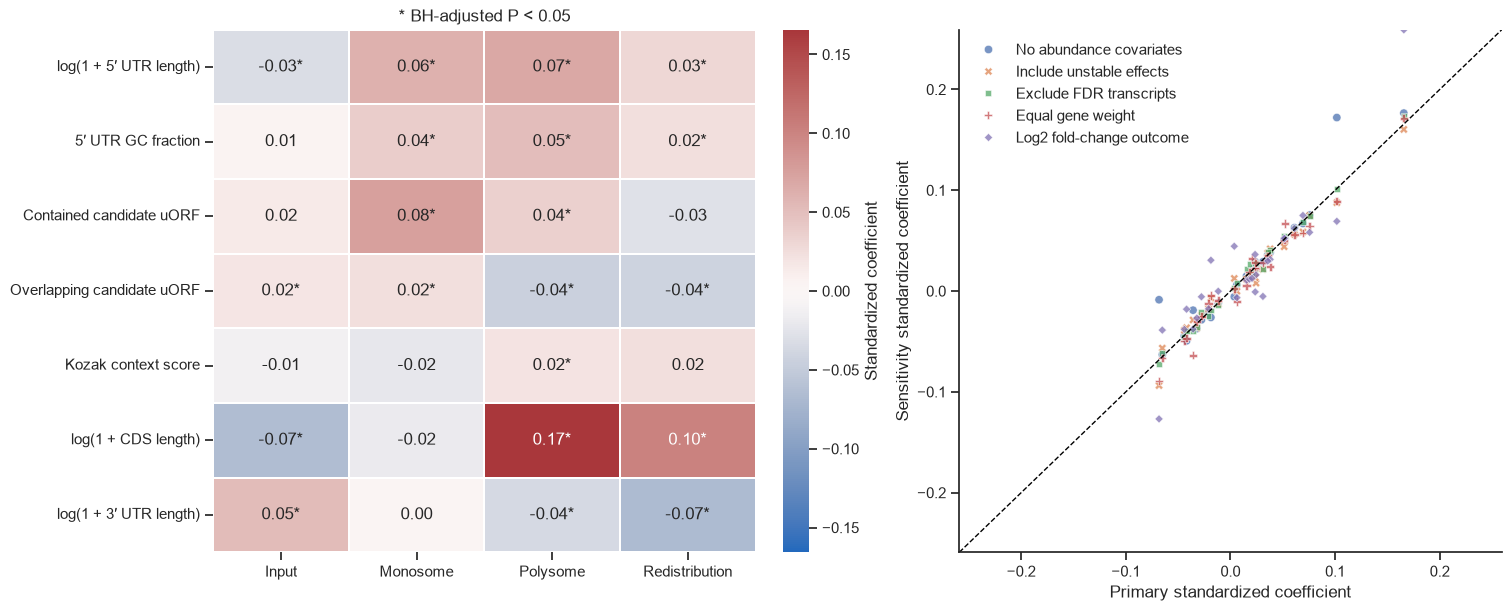

In [8]:
# Visualize association direction, multiplicity, and sensitivity.

association_matrix = feature_association.pivot(
    index = 'featureLabel',
    columns = 'analysis',
    values = 'standardizedCoefficient',
).reindex(
    index = [FEATURES[feature]['label'] for feature in JOINT_FEATURES],
    columns = ANALYSES,
)
qvalue_matrix = feature_association.pivot(
    index = 'featureLabel',
    columns = 'analysis',
    values = 'adjustedPValue',
).reindex(index = association_matrix.index, columns = association_matrix.columns)
annotations = association_matrix.map(lambda value: f'{value:.2f}')
annotations = annotations + qvalue_matrix.map(
    lambda value: '*' if pd.notna(value) and value < ALPHA else ''
)

figure, axes = plt.subplots(1, 2, figsize = (15, 6), constrained_layout = True)
limit = np.nanmax(np.abs(association_matrix.to_numpy()))
sns.heatmap(
    association_matrix.rename(columns = LABELS),
    annot = annotations,
    fmt = '',
    cmap = 'vlag',
    center = 0,
    vmin = -limit,
    vmax = limit,
    linewidths = 0.25,
    linecolor = 'white',
    cbar_kws = {'label': 'Standardized coefficient'},
    ax = axes[0],
)
axes[0].set(xlabel = '', ylabel = '', title = '* BH-adjusted P < 0.05')

plot_sensitivity = feature_sensitivity.loc[
    ~feature_sensitivity['variant'].eq('primary')
].copy()
variant_labels = {
    'unadjusted': 'No abundance covariates',
    'includeUnstable': 'Include unstable effects',
    'excludeFdr': 'Exclude FDR transcripts',
    'geneBalanced': 'Equal gene weight',
    'effectSize': 'Log2 fold-change outcome',
}
plot_sensitivity['model'] = plot_sensitivity['variant'].map(variant_labels)
sns.scatterplot(
    data = plot_sensitivity,
    x = 'primaryCoefficient',
    y = 'standardizedCoefficient',
    hue = 'model',
    style = 'model',
    alpha = 0.75,
    ax = axes[1],
)
axis_limit = np.nanmax(
    np.abs(
        plot_sensitivity[
            ['primaryCoefficient', 'standardizedCoefficient']
        ].to_numpy()
    )
)
axes[1].plot(
    [-axis_limit, axis_limit],
    [-axis_limit, axis_limit],
    color = 'black',
    linewidth = 1,
    linestyle = '--',
)
axes[1].set(
    xlim = (-axis_limit, axis_limit),
    ylim = (-axis_limit, axis_limit),
    xlabel = 'Primary standardized coefficient',
    ylabel = 'Sensitivity standardized coefficient',
)
axes[1].legend(title = '', frameon = False)
sns.despine(ax = axes[1])
plt.show()


In [9]:
# Save complete feature tables, model diagnostics, and software provenance.

transcript_features.reset_index().to_csv(
    RESULTS_DIR / 'transcriptFeatures.tsv',
    sep = '\t',
    index = False,
    na_rep = 'NA',
)
feature_audit.to_csv(
    RESULTS_DIR / 'transcriptFeatureAudit.tsv',
    sep = '\t',
    index = False,
)
feature_eligibility.to_csv(
    RESULTS_DIR / 'transcriptFeatureEligibility.tsv',
    sep = '\t',
    index = False,
)
feature_association.to_csv(
    RESULTS_DIR / 'transcriptFeatureAssociation.tsv',
    sep = '\t',
    index = False,
    na_rep = 'NA',
)
marginal_association.to_csv(
    RESULTS_DIR / 'transcriptFeatureMarginalAssociation.tsv',
    sep = '\t',
    index = False,
    na_rep = 'NA',
)
model_comparison.to_csv(
    RESULTS_DIR / 'transcriptFeatureModelComparison.tsv',
    sep = '\t',
    index = False,
    na_rep = 'NA',
)
feature_sensitivity.to_csv(
    RESULTS_DIR / 'transcriptFeatureSensitivity.tsv',
    sep = '\t',
    index = False,
    na_rep = 'NA',
)
sensitivity_summary.to_csv(
    RESULTS_DIR / 'transcriptFeatureSensitivitySummary.tsv',
    sep = '\t',
    index = False,
    na_rep = 'NA',
)
candidate_summary.to_csv(
    RESULTS_DIR / 'transcriptFeatureCandidates.tsv',
    sep = '\t',
    index = False,
    na_rep = 'NA',
)

software = {
    package: version(package)
    for package in (
        'numpy',
        'pandas',
        'scipy',
        'statsmodels',
        'matplotlib',
        'seaborn',
    )
}
provenance = {
    'analysisUnit': 'GENCODE v50 transcript',
    'contrast': f'{TEST} versus {REFERENCE}',
    'annotation': gtf_header[0].removeprefix('##description: '),
    'transcriptFasta': {
        'path': str(FASTA_PATH.relative_to(ROOT)),
        'bytes': FASTA_PATH.stat().st_size,
        'source': (
            'nf-core/rnaseq run-matched genome.transcripts.fa generated from '
            'the analysis genome and filtered GTF'
        ),
    },
    'featureUniverse': (
        'union of transcripts tested in input, monosome, polysome, or '
        'redistribution abundance models'
    ),
    'architectureEligibility': (
        'protein-coding transcript with concordant FASTA/exon length, only '
        'ACGT sequence, complete annotated start and stop codons, ATG main '
        'start, and concordant UTR and coding lengths'
    ),
    'candidateUorfDefinition': (
        'AUG in the annotated 5-prime UTR followed in frame by a stop codon '
        'before the main start; overlapping candidates lack such a stop '
        'before the main start'
    ),
    'candidateUorfInterpretation': (
        'sequence prediction only; translation requires orthogonal evidence'
    ),
    'threePrimeUtrDefinition': (
        'bases after the annotated stop codon; the GENCODE generic UTR '
        'feature includes the stop codon and is adjusted during validation'
    ),
    'kozakScore': (
        'one point for A/G at position -3 and one point for G at position +4'
    ),
    'primaryModel': (
        'within-parent-gene centered standardized transcript Wald statistic '
        'jointly regressed on the seven nonredundant centered standardized '
        'architecture features, centered log base mean, and centered logit '
        'mean gene proportion; gene-clustered standard errors'
    ),
    'upstreamAugModelRole': (
        'any upstream AUG is a marginal-only descriptor because it is the '
        'union of contained and overlapping candidate uORF indicators'
    ),
    'marginalModel': (
        'one architecture feature at a time with the primary covariates and '
        'exclusions; retained as a transparent screen, not an independent '
        'feature effect'
    ),
    'primaryExclusions': (
        'structural-zero or extreme transcript effects flagged by Notebook 09'
    ),
    'multipleTesting': (
        'Benjamini-Hochberg across seven joint-model features and four layers within '
        'each model variant'
    ),
    'sensitivityModels': list(VARIANTS),
    'methodReferences': {
        'GENCODE': 'https://doi.org/10.1093/nar/gky955',
        'KozakContext': 'https://doi.org/10.1093/nar/15.20.8125',
        'fivePrimeUtrAssay': 'https://doi.org/10.1038/s41587-019-0164-5',
        'autismFivePrimeUtr': 'https://doi.org/10.1101/2023.11.02.23297961',
    },
    'software': software,
}
(RESULTS_DIR / 'transcriptFeatureProvenance.json').write_text(
    json.dumps(provenance, indent = 2),
    encoding = 'utf-8',
)


2677